# EDA - IBM HR Analytics Employee Attrition

Análise exploratória do dataset de attrition de RH.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

df = pd.read_csv("../data/HR-Employee-Attrition-processed.csv")
df_raw = pd.read_csv("../data/HR-Employee-Attrition.csv")

print(f"Processado: {df.shape}")
df.head()

Processado: (1470, 44)


,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,18,1,2,1306,5,3,2,M,69,3,...,0,0,0,0,0,0,0,1,0,1
1,18,1,0,247,8,1,3,M,80,3,...,0,1,0,0,0,0,0,0,0,1
2,18,1,2,544,3,2,2,F,70,3,...,0,0,0,0,0,0,0,1,0,1
3,18,0,0,1431,14,3,2,F,33,3,...,0,0,0,0,0,1,0,0,0,1
4,18,0,1,812,10,3,4,F,69,2,...,0,0,0,0,0,0,0,1,0,1


## 1. Distribuição de Attrition

Taxa de attrition: 16.1%


/tmp/ipykernel_172208/2194445809.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_raw, x="Attrition", palette="Set2", ax=axes[0])


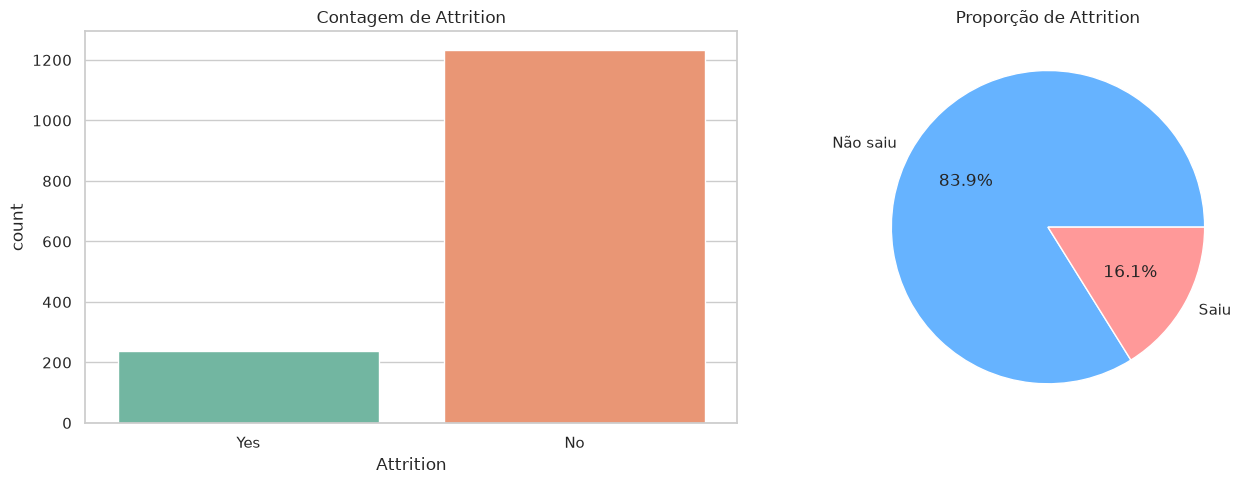

In [2]:
attrition_rate = df["Attrition"].mean() * 100
print(f"Taxa de attrition: {attrition_rate:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_raw, x="Attrition", palette="Set2", ax=axes[0])
axes[0].set_title("Contagem de Attrition")

df["Attrition"].value_counts().plot.pie(
    autopct="%1.1f%%", labels=["Não saiu", "Saiu"],
    colors=["#66b3ff", "#ff9999"], ax=axes[1]
)
axes[1].set_title("Proporção de Attrition")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 2. Attrition por Idade

/tmp/ipykernel_172208/4032248869.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x="Attrition", y="Age", palette="Set2", ax=axes[1])


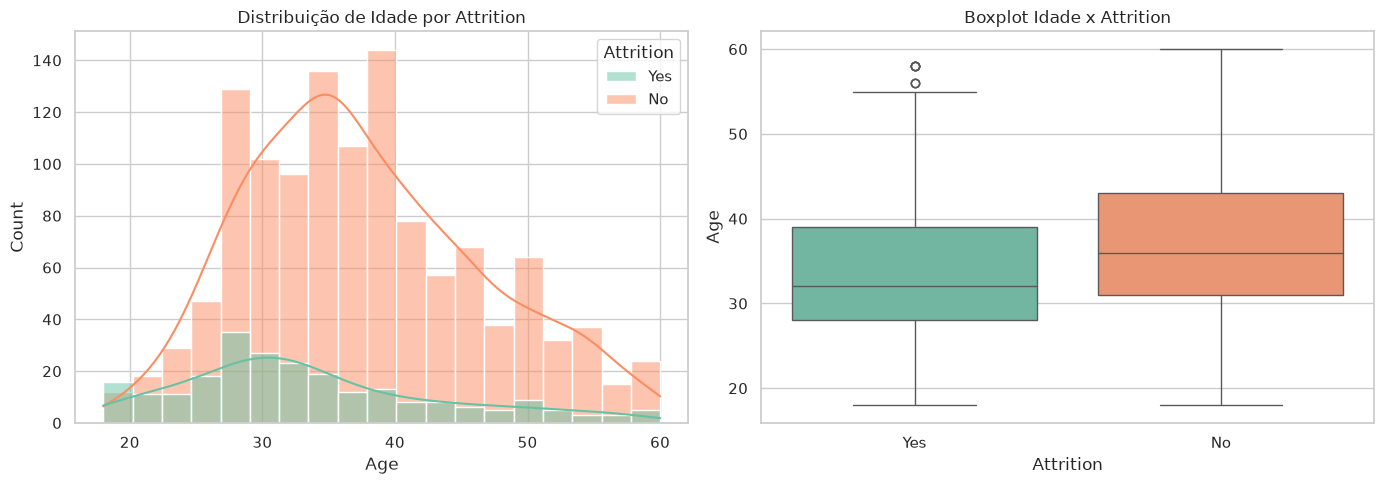

Idade média:
Attrition
No     37.561233
Yes    33.607595
Name: Age, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_raw, x="Age", hue="Attrition", kde=True, palette="Set2", ax=axes[0])
axes[0].set_title("Distribuição de Idade por Attrition")

sns.boxplot(data=df_raw, x="Attrition", y="Age", palette="Set2", ax=axes[1])
axes[1].set_title("Boxplot Idade x Attrition")

plt.tight_layout()
plt.show()

print("Idade média:")
print(df_raw.groupby("Attrition")["Age"].mean())

## 3. Attrition por Departamento

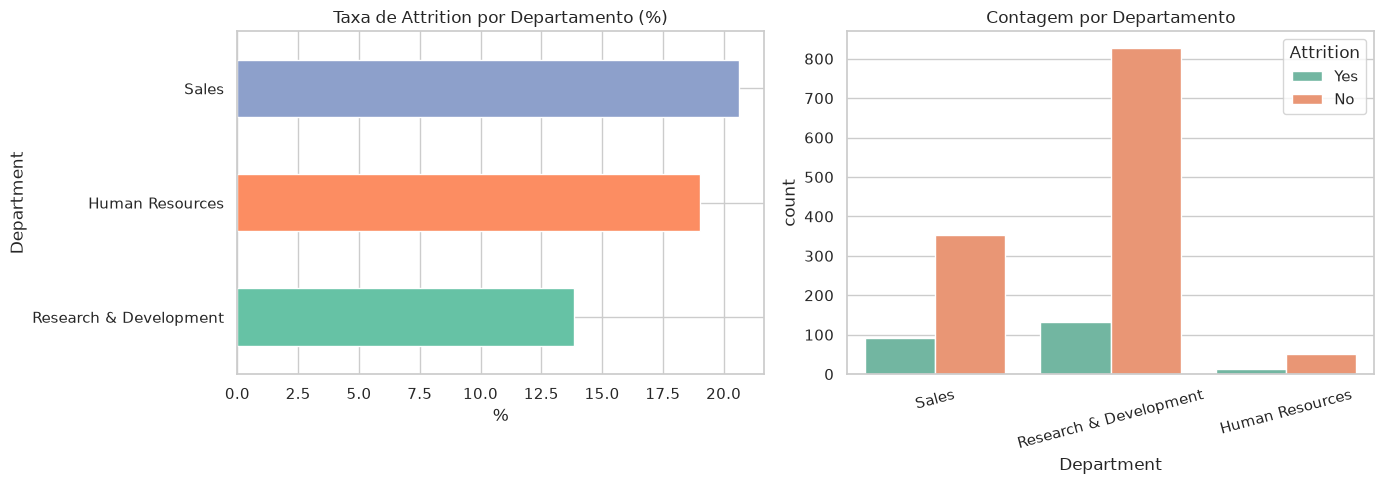

Department
Research & Development    13.8
Human Resources           19.0
Sales                     20.6
Name: Attrition, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dept_attrition = df_raw.groupby("Department")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=True)

dept_attrition.plot.barh(color=sns.color_palette("Set2", len(dept_attrition)), ax=axes[0])
axes[0].set_title("Taxa de Attrition por Departamento (%)")
axes[0].set_xlabel("%")

sns.countplot(data=df_raw, x="Department", hue="Attrition", palette="Set2", ax=axes[1])
axes[1].set_title("Contagem por Departamento")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

print(dept_attrition.round(1))

## 4. Attrition por Salário

/tmp/ipykernel_172208/33729914.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x="Attrition", y="MonthlyIncome", palette="Set2", ax=axes[0])


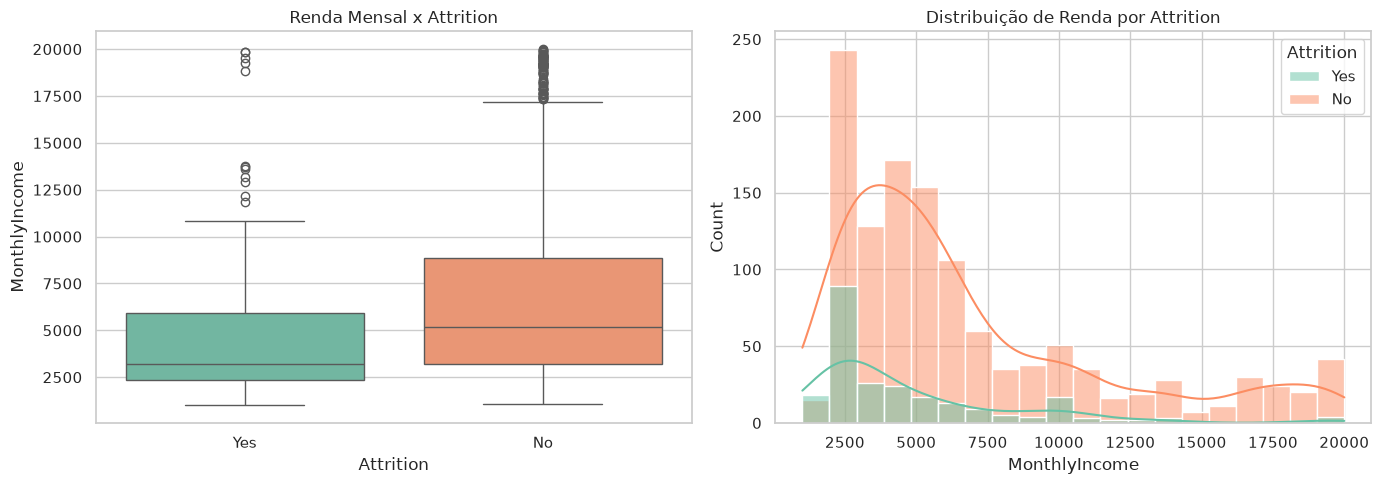

Renda média:
Attrition
No     6833.0
Yes    4787.0
Name: MonthlyIncome, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_raw, x="Attrition", y="MonthlyIncome", palette="Set2", ax=axes[0])
axes[0].set_title("Renda Mensal x Attrition")

sns.histplot(data=df_raw, x="MonthlyIncome", hue="Attrition", kde=True, palette="Set2", ax=axes[1])
axes[1].set_title("Distribuição de Renda por Attrition")

plt.tight_layout()
plt.show()

print("Renda média:")
print(df_raw.groupby("Attrition")["MonthlyIncome"].mean().round(0))

## 5. Attrition por Gênero e Job Role

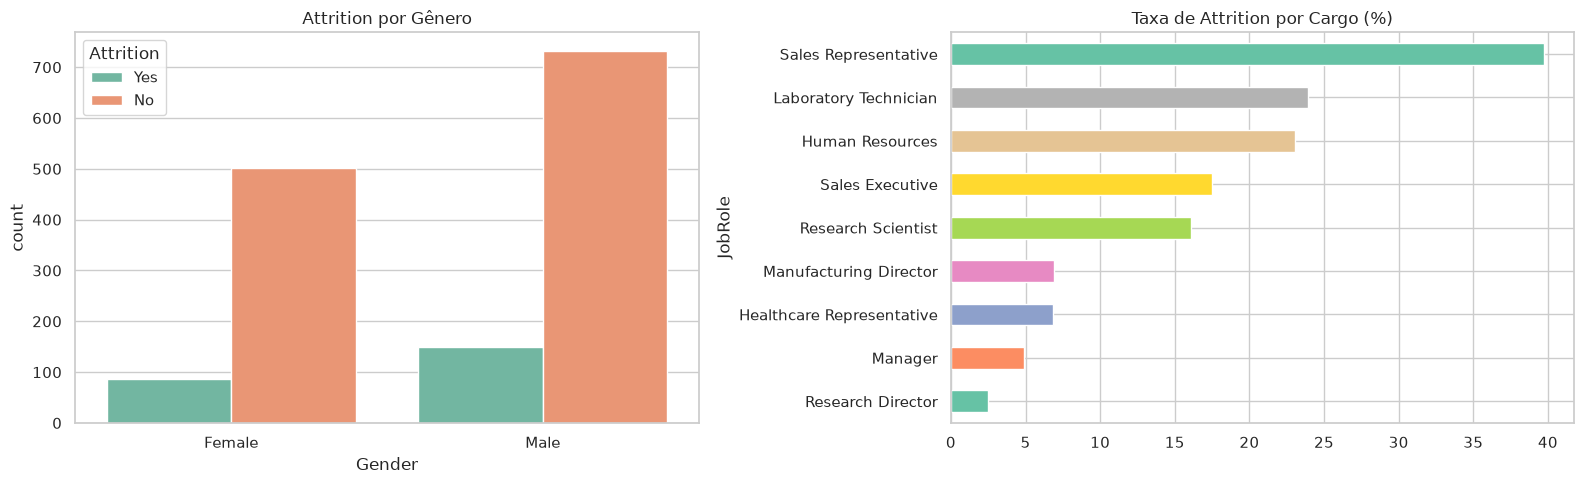

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(data=df_raw, x="Gender", hue="Attrition", palette="Set2", ax=axes[0])
axes[0].set_title("Attrition por Gênero")

job_attrition = df_raw.groupby("JobRole")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=True)

job_attrition.plot.barh(color=sns.color_palette("Set2", len(job_attrition)), ax=axes[1])
axes[1].set_title("Taxa de Attrition por Cargo (%)")

plt.tight_layout()
plt.show()

## 6. Correlação com Attrition

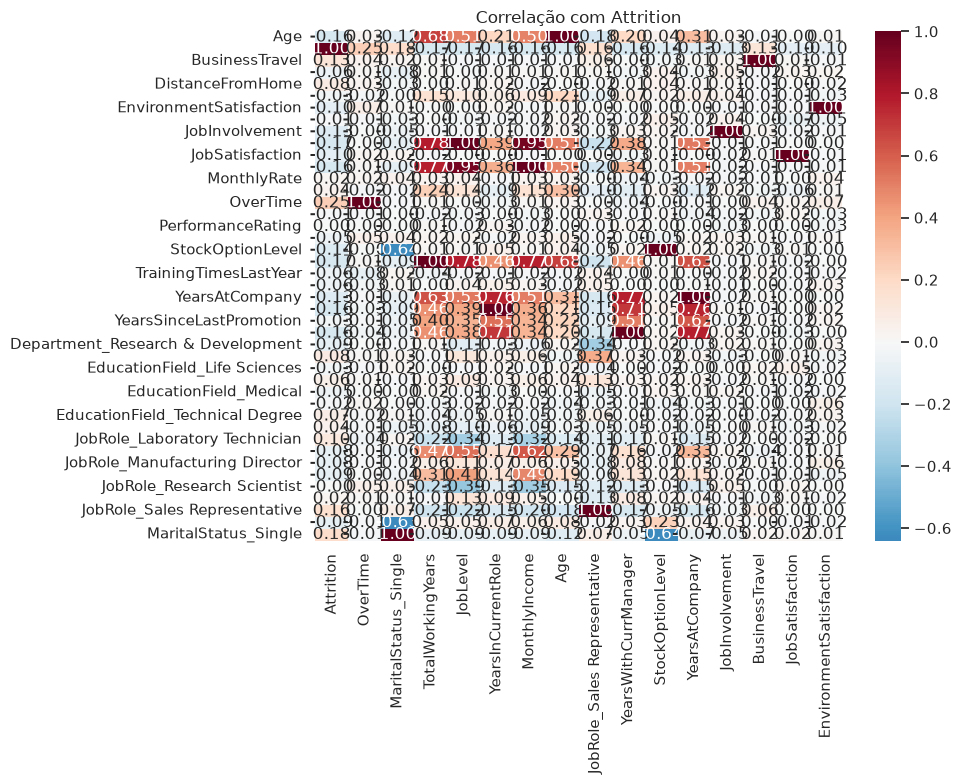

Top correlações com Attrition:
OverTime                             0.246
MaritalStatus_Single                 0.175
TotalWorkingYears                   -0.171
JobLevel                            -0.169
YearsInCurrentRole                  -0.161
MonthlyIncome                       -0.160
Age                                 -0.159
JobRole_Sales Representative         0.157
YearsWithCurrManager                -0.156
StockOptionLevel                    -0.137
YearsAtCompany                      -0.134
JobInvolvement                      -0.130
BusinessTravel                       0.127
JobSatisfaction                     -0.103
EnvironmentSatisfaction             -0.103
JobRole_Laboratory Technician        0.098
MaritalStatus_Married               -0.091
JobRole_Research Director           -0.089
Department_Research & Development   -0.085
JobRole_Manager                     -0.083
JobRole_Manufacturing Director      -0.083
Department_Sales                     0.081
DistanceFromHome       

In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
corr = df[numeric_cols].corr()

attrition_corr = corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
top_cols = attrition_corr.index[:15].tolist()
sns.heatmap(
    corr[["Attrition"] + top_cols].round(2),
    annot=True, cmap="RdBu_r", center=0, fmt=".2f", ax=ax
)
ax.set_title("Correlação com Attrition")

plt.tight_layout()
plt.show()

print("Top correlações com Attrition:")
print(attrition_corr.round(3).to_string())

## 7. Satisfação e Work-Life Balance

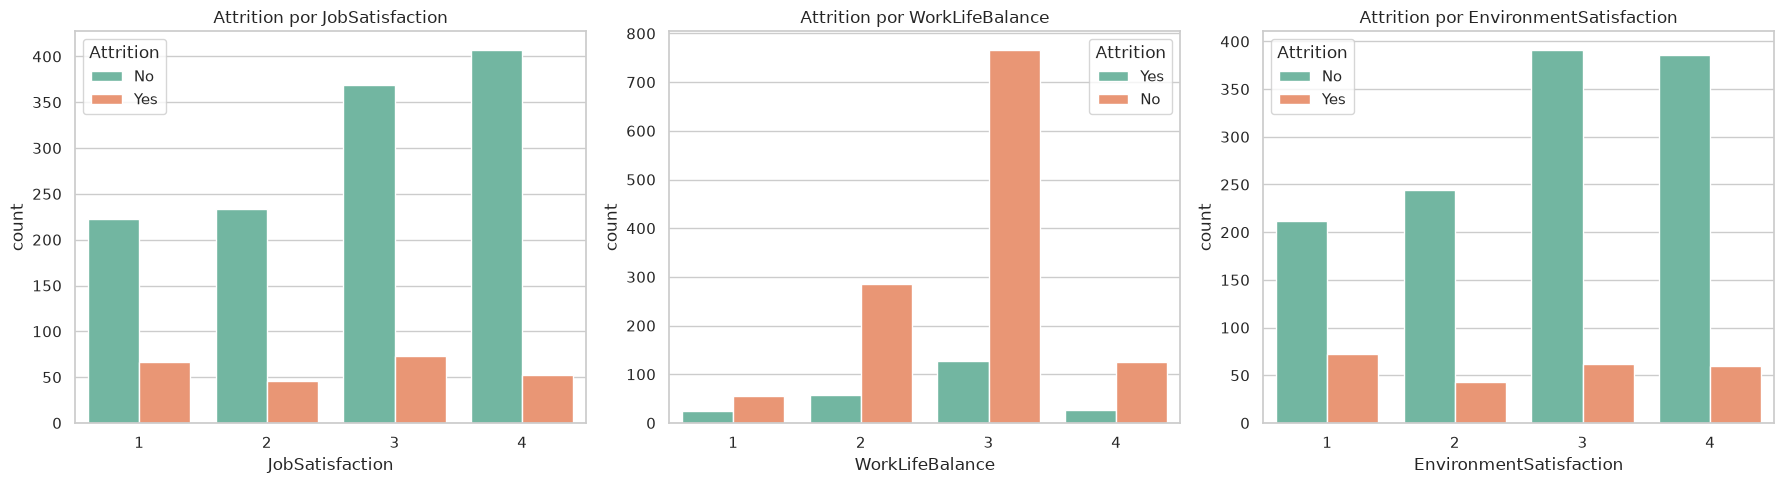

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(["JobSatisfaction", "WorkLifeBalance", "EnvironmentSatisfaction"]):
    sns.countplot(data=df_raw, x=col, hue="Attrition", palette="Set2", ax=axes[i])
    axes[i].set_title(f"Attrition por {col}")

plt.tight_layout()
plt.show()

## 8. Anos na Empresa x Attrition

/tmp/ipykernel_172208/1730785782.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x="Attrition", y="YearsAtCompany", palette="Set2", ax=axes[1])


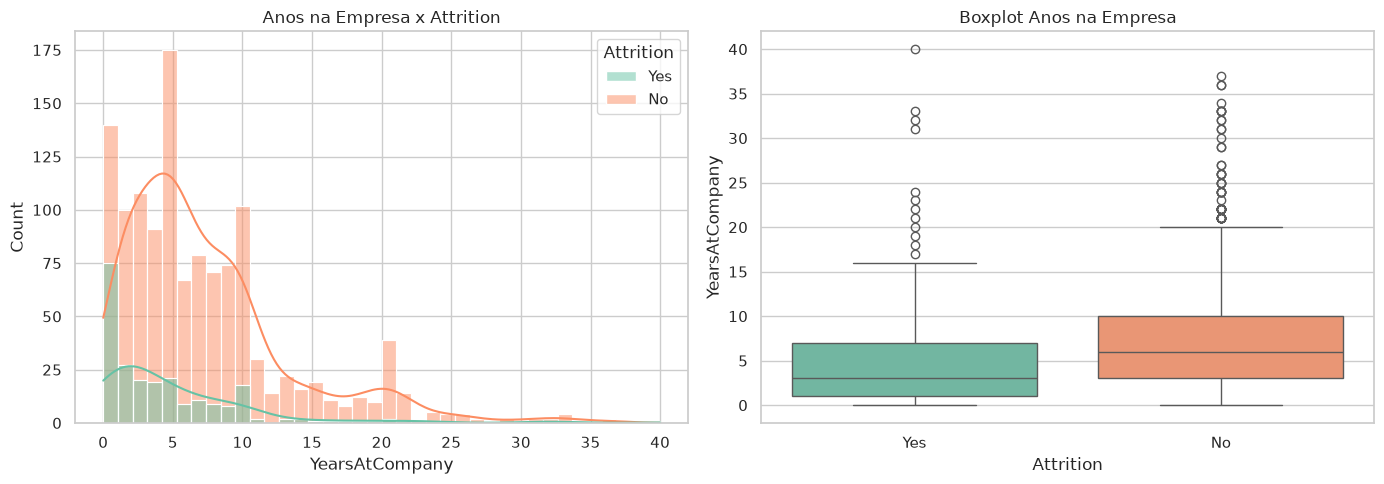

Anos na empresa (média):
Attrition
No     7.4
Yes    5.1
Name: YearsAtCompany, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_raw, x="YearsAtCompany", hue="Attrition", kde=True, palette="Set2", ax=axes[0])
axes[0].set_title("Anos na Empresa x Attrition")

sns.boxplot(data=df_raw, x="Attrition", y="YearsAtCompany", palette="Set2", ax=axes[1])
axes[1].set_title("Boxplot Anos na Empresa")

plt.tight_layout()
plt.show()

print("Anos na empresa (média):")
print(df_raw.groupby("Attrition")["YearsAtCompany"].mean().round(1))

## Resumo

- Taxa de attrition: ~16%
- Quem sai tende a ser mais jovem e com menor salário
- Laboratory Technician e Sales Representative têm maior attrition
- Menor satisfação no trabalho e work-life balance correlacionam com saída